# TN Scene Footprint: 7 Sites / 21 Sector Cells

Retain **central site 1 and first-ring sites 2–7** from the original 19-site layout, removing the 12 second-ring sites.
Each site retains three sectors, with each sector corresponding to one complete small hexagonal cell. The inter-site distance is unchanged.
This notebook computes geometry and plots for Blender land planning, site placement, and subsequent cropping.

The geometry follows the project's
[`generateTnNetwork.m`](../NTN_TN_CO/Functions_TN_Geometry/generateTnNetwork.m),
[`plotTnSectorHexagons.m`](../NTN_TN_CO/Functions_Plotting/plotTnSectorHexagons.m), and
[`NTN_TN_Coex.m`](../NTN_TN_CO/NTN_TN_Coex.m).
The last file uses ISD = 750 m and BS height = 25 m for UMa, and ISD = 7500 m and BS height = 30 m for RMa.

**Usage:** Edit the parameter cell below, then select Run All. Outputs include a comparison with the original layout,
a detailed 21-cell plot, land dimensions, site/sector CSV files, and a JSON file containing the hexagonal vertices.
All lengths are in **metres**, with coordinates **X = East, Y = North, Z = Up**.

The original 3GPP documents are saved in this directory:

| Document | Relevant parameter table | RMa parameters |
|---|---|---|
| [TR 38.863 V19.4.0](38863-j40.docx) | Table 6.2.2.4-2, 2 GHz TN coexistence scenario | ISD = 7500 m, BS height = 30 m |
| [TR 38.901 V19.3.0](38901-j30.docx) | Table 7.2-3, RMa evaluation scenario | ISD = 1732 or 5000 m, BS height = 35 m |

The current defaults correspond to the TR 38.863 RMa configuration. The three sector orientations follow this project's definitions.


In [1]:
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Polygon, Rectangle, Patch
from matplotlib.lines import Line2D
from matplotlib.path import Path as MplPath
from IPython.display import display, Markdown

# Use Times New Roman when installed, otherwise use a compatible serif font.
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
plot_font = next((name for name in ['Times New Roman', 'Nimbus Roman',
                                   'Liberation Serif', 'DejaVu Serif']
                  if name in available_fonts), 'DejaVu Serif')
plt.rcParams.update({
    'font.family': plot_font, 'font.size': 12,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'text.color': 'black',
    'axes.labelcolor': 'black', 'axes.titlecolor': 'black',
    'xtick.color': 'black', 'ytick.color': 'black',
    'axes.spines.top': False, 'axes.spines.right': False,
    'svg.fonttype': 'none', 'pdf.fonttype': 42,
})
print(f'Plot font: {plot_font}')

Plot font: Nimbus Roman


In [2]:
# Change these parameters, then run all cells again.
SCENARIO = 'RMa'                 # 'UMa' or 'RMa'; matches the source default.
ISD_OVERRIDE_M = None            # Optional custom spacing, e.g. 500.0.
MARGIN_M = 0.0                   # Extra land on EACH side of the cell boundary.
ROUND_UP_M = 10.0                # Round land dimensions upward to this increment.
RECTANGLE_MODE = 'tight'        # 'tight' or 'site_centered'.

PRESETS = {'UMa': {'isd_m': 750.0, 'bs_height_m': 25.0},
           'RMa': {'isd_m': 7500.0, 'bs_height_m': 30.0}}
assert SCENARIO in PRESETS
assert RECTANGLE_MODE in ('tight', 'site_centered')
ISD_M = float(PRESETS[SCENARIO]['isd_m'] if ISD_OVERRIDE_M is None
              else ISD_OVERRIDE_M)
BS_HEIGHT_M = PRESETS[SCENARIO]['bs_height_m']
UE_HEIGHT_M = 1.5
assert np.isfinite(ISD_M) and ISD_M > 0
assert np.isfinite(MARGIN_M) and MARGIN_M >= 0
assert np.isfinite(ROUND_UP_M) and ROUND_UP_M > 0

# Resolve the output folder from the notebook directory or a project ancestor.
cwd = Path.cwd().resolve()
if cwd.name == 'For NTN Nulling Simu':
    notebook_dir = cwd
else:
    notebook_dir = next((p / 'For NTN Nulling Simu' for p in [cwd, *cwd.parents]
                         if (p / 'For NTN Nulling Simu').is_dir()), cwd)
OUT_DIR = notebook_dir / 'tn_7site_layout'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'{SCENARIO}: ISD = {ISD_M:g} m, BS height = {BS_HEIGHT_M:g} m')
print(f'Output folder: {OUT_DIR}')

RMa: ISD = 7500 m, BS height = 30 m
Output folder: /home/shizhen/my_project/CL_Project/CL_Project/For NTN Nulling Simu/tn_7site_layout


## Geometry and Numbering

Site positions follow the axial coordinates and ordering in the original code:
\(x=D(q+r/2),\ y=D\sqrt{3}r/2\), where \(D=\mathrm{ISD}\).
At each site, the three cells have circumradius \(R=D/3\), with centers at
\(\boldsymbol c=\boldsymbol s+R(\cos\theta,\sin\theta)\)
and six vertices at \(\boldsymbol c+R(\cos k\pi/3,\sin k\pi/3)\).

The sector order follows the **current main program**: `[60, 180, 300]` degrees, measured counterclockwise from +X.
The older `grid_cell_layout_7sites_3sectors.m` uses `[300, 180, 60]`: the coverage geometry is identical, but local sector IDs 1 and 3 are swapped at each site.
**Transmitters are located at the site, not at the centers of the small hexagons**; the three sectors share a position but have different orientations.

**Site triangle orientation:** Following the original project's
[`plotTnSiteSectorTriangles.m`](../NTN_TN_CO/Functions_Plotting/plotTnSiteSectorTriangles.m),
the three **vertices** point along the site's three panel azimuths, currently **60°, 180°, and 300°**.
One triangle vertex therefore points due west. The colored arrows extend from each site toward the corresponding cell centers.

| Local sector | Triangle vertex / panel azimuth (counterclockwise from East) | Compass bearing (clockwise from North) |
|---|---:|---:|
| 1 | 60° | 30° |
| 2 | 180° | 270° |
| 3 | 300° | 150° |

The triangle is an orientation symbol; its size does not represent the physical antenna dimensions.
All angles are **horizontal azimuths viewed from above**. Vertical downtilt and electrical beam steering must be configured separately.


In [3]:
# Preserve the site order in generateTnNetwork.m.
AXIAL_19 = np.array([
    [0, 0],
    [1, 0], [1, -1], [0, -1], [-1, 0], [-1, 1], [0, 1],
    [2, 0], [2, -1], [2, -2], [1, -2], [0, -2], [-1, -1],
    [-2, 0], [-2, 1], [-2, 2], [-1, 2], [0, 2], [1, 1],
], dtype=int)
AZIMUTH_DEG = np.array([60.0, 180.0, 300.0])

def make_layout(isd_m, number_of_sites):
    axial = AXIAL_19[:number_of_sites]
    sites = isd_m * np.column_stack((axial[:, 0] + 0.5 * axial[:, 1],
                                    np.sqrt(3) / 2 * axial[:, 1]))
    radius = isd_m / 3
    directions = np.column_stack((np.cos(np.deg2rad(AZIMUTH_DEG)),
                                  np.sin(np.deg2rad(AZIMUTH_DEG))))
    centers = (sites[:, None, :] + radius * directions[None, :, :]).reshape(-1, 2)
    vertex_angles = np.arange(6) * np.pi / 3
    offsets = radius * np.column_stack((np.cos(vertex_angles), np.sin(vertex_angles)))
    vertices = centers[:, None, :] + offsets[None, :, :]
    return {'sites': sites, 'centers': centers, 'vertices': vertices,
            'site_ids': np.repeat(np.arange(1, number_of_sites + 1), 3),
            'sector_at_site': np.tile(np.arange(1, 4), number_of_sites),
            'sector_ids': np.arange(1, 3 * number_of_sites + 1),
            'azimuth_deg': np.tile(AZIMUTH_DEG, number_of_sites),
            'radius_m': radius}

def rectangle_for(layout, mode='tight', margin_m=0.0, round_up_m=None):
    points = layout['vertices'].reshape(-1, 2)
    low, high = points.min(axis=0), points.max(axis=0)
    if mode == 'tight':
        center, size = (low + high) / 2, high - low
    elif mode == 'site_centered':
        center, size = np.zeros(2), 2 * np.maximum(np.abs(low), np.abs(high))
    else:
        raise ValueError('Unknown rectangle mode')
    size = size + 2 * margin_m
    if round_up_m is not None:
        size = np.ceil(size / round_up_m) * round_up_m
    return {'center': center, 'size': size,
            'min': center - size / 2, 'max': center + size / 2}

layout19 = make_layout(ISD_M, 19)
layout = make_layout(ISD_M, 7)
tight = rectangle_for(layout)
centered = rectangle_for(layout, 'site_centered')
land = rectangle_for(layout, RECTANGLE_MODE, MARGIN_M, ROUND_UP_M)
print(f"Selected: {len(layout['sites'])} sites / {len(layout['vertices'])} cells")

Selected: 7 sites / 21 cells


## Bounding Rectangle Dimensions

Here, "minimum" means the **East/North-aligned** rectangle containing all 21 complete cells, computed from all 126 vertices.
Before adding margins or rounding:

\[
x_{\min}=-\frac{5D}{3},\quad x_{\max}=\frac{3D}{2},\quad
y_{\min/\max}=\mp\frac{5\sqrt{3}D}{6}.
\]
\[
\boxed{W_X=\frac{19D}{6},\quad L_Y=\frac{5\sqrt{3}D}{3}},\qquad
\boldsymbol c_{\mathrm{rect}}=(-D/12,\ 0).
\]

If both the land center and site 1 must be at `(0, 0)`, the X dimension becomes \(10D/3\), while the Y dimension is unchanged.
The Blender modeling dimensions below include the expansion specified by `MARGIN_M` and `ROUND_UP_M`.


In [4]:
def size_text(rect):
    return f"{rect['size'][0]:,.3f} × {rect['size'][1]:,.3f}"

rows = ['| Scenario | ISD (m) | Minimum rectangle X × Y (m) | Minimum rectangle center (m) | Site-centered rectangle X × Y (m) |',
        '|---|---:|---:|---:|---:|']
for name, preset in PRESETS.items():
    sample = make_layout(preset['isd_m'], 7)
    a, b = rectangle_for(sample), rectangle_for(sample, 'site_centered')
    rows.append(f"| {name} | {preset['isd_m']:g} | {size_text(a)} | "
                f"({a['center'][0]:g}, 0) | {size_text(b)} |")
display(Markdown('\n'.join(rows)))

dimensions = [
    '| Rectangle for current parameters | X × Y (m) | Center (X, Y), m |',
    '|---|---:|---:|',
]
for label, rect in [('Minimum bounding rectangle', tight), ('Site-centered rectangle', centered),
                    (f'Blender modeling area ({RECTANGLE_MODE})', land)]:
    dimensions.append(f"| {label} | {size_text(rect)} | "
                      f"({rect['center'][0]:.3f}, {rect['center'][1]:.3f}) |")
display(Markdown('\n'.join(dimensions)))
print(f"Blender land X range: [{land['min'][0]:.6f}, {land['max'][0]:.6f}] m")
print(f"Blender land Y range: [{land['min'][1]:.6f}, {land['max'][1]:.6f}] m")
print(f"Blender land dimensions: X = {land['size'][0]:g} m, Y = {land['size'][1]:g} m")
print(f"Land center: ({land['center'][0]:g}, {land['center'][1]:g}, 0) m")

| Scenario | ISD (m) | Minimum rectangle X × Y (m) | Minimum rectangle center (m) | Site-centered rectangle X × Y (m) |
|---|---:|---:|---:|---:|
| UMa | 750 | 2,375.000 × 2,165.064 | (-62.5, 0) | 2,500.000 × 2,165.064 |
| RMa | 7500 | 23,750.000 × 21,650.635 | (-625, 0) | 25,000.000 × 21,650.635 |

| Rectangle for current parameters | X × Y (m) | Center (X, Y), m |
|---|---:|---:|
| Minimum bounding rectangle | 23,750.000 × 21,650.635 | (-625.000, 0.000) |
| Site-centered rectangle | 25,000.000 × 21,650.635 | (0.000, 0.000) |
| Blender modeling area (tight) | 23,750.000 × 21,660.000 | (-625.000, 0.000) |

Blender land X range: [-12500.000000, 11250.000000] m
Blender land Y range: [-10830.000000, 10830.000000] m
Blender land dimensions: X = 23750 m, Y = 21660 m
Land center: (-625, 0, 0) m


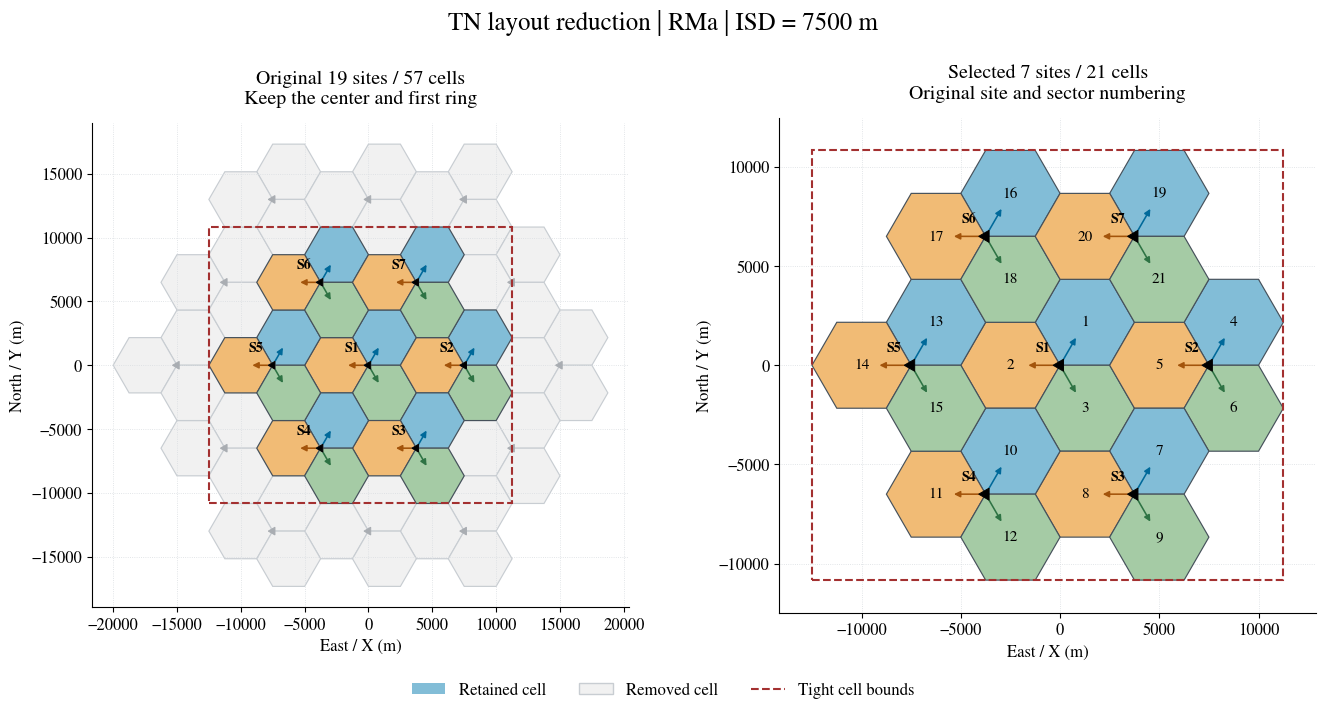

In [5]:
COLORS = ['#82BDD7', '#F1BB75', '#A5CBA5']
DIRECTION_COLORS = ['#00699A', '#A3540B', '#2E7344']

def unit_xy(angle_deg):
    angles = np.deg2rad(np.asarray(angle_deg, dtype=float))
    return np.stack((np.cos(angles), np.sin(angles)), axis=-1)

def site_symbol_geometry(data, site_id):
    # The three vertices use the actual sector azimuths, matching MATLAB.
    site = data['sites'][site_id - 1]
    rows = np.flatnonzero(data['site_ids'] == site_id)
    directions = unit_xy(data['azimuth_deg'][rows])
    if directions.shape != (3, 2):
        raise ValueError('A site symbol requires exactly three sectors.')
    tips = site + 0.14 * data['radius_m'] * directions
    arrow_ends = site + 0.64 * data['radius_m'] * directions
    return site, rows, directions, tips, arrow_ends

legend_tips = unit_xy(AZIMUTH_DEG)
SITE_MARKER = MplPath(np.vstack((legend_tips, legend_tips[0])), closed=True)

def draw_cells(ax, data, active=True, label_cells=False, label_sites=False,
               show_boresights=True):
    for i, vertices in enumerate(data['vertices']):
        ax.add_patch(Polygon(vertices, closed=True,
                             facecolor=COLORS[i % 3] if active else '#F1F1F1',
                             edgecolor='#46515B' if active else '#C8CDD2',
                             linewidth=0.85, zorder=2 if active else 1))
        if label_cells:
            x, y = data['centers'][i]
            ax.text(x, y, str(data['sector_ids'][i]), ha='center', va='center',
                    fontsize=11, zorder=5)
    for site_id in range(1, len(data['sites']) + 1):
        site, rows, directions, tips, arrow_ends = site_symbol_geometry(data, site_id)
        color = 'black' if active else '#A9ADB2'
        ax.add_patch(Polygon(tips, closed=True, facecolor=color,
                             edgecolor=color, linewidth=0.7, zorder=6))
        if active and show_boresights:
            for local_id, tip, endpoint in zip(data['sector_at_site'][rows], tips, arrow_ends):
                ax.annotate('', xy=endpoint, xytext=tip,
                            arrowprops={'arrowstyle': '-|>', 'lw': 1.15,
                                        'color': DIRECTION_COLORS[local_id - 1],
                                        'mutation_scale': 9, 'shrinkA': 0, 'shrinkB': 0},
                            zorder=5)
        if label_sites:
            ax.annotate(f'S{site_id}', site, xytext=(-7, 10),
                        textcoords='offset points', ha='right', fontsize=10,
                        fontweight='bold', zorder=7)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('East / X (m)')
    ax.set_ylabel('North / Y (m)')
    ax.grid(True, linestyle=':', color='#D9DDE1', linewidth=0.6, zorder=0)
    ax.ticklabel_format(style='plain', useOffset=False)

def draw_rectangle(ax, rect, color='#A33030', linestyle='--', linewidth=1.5):
    ax.add_patch(Rectangle(rect['min'], *rect['size'], fill=False,
                           edgecolor=color, linestyle=linestyle,
                           linewidth=linewidth, zorder=8))

fig_overview, axes = plt.subplots(1, 2, figsize=(13.6, 7.65))
draw_cells(axes[0], layout19, active=False)
draw_cells(axes[0], layout, label_sites=True)
draw_rectangle(axes[0], tight)
axes[0].set_title('Original 19 sites / 57 cells\nKeep the center and first ring', pad=14)
draw_cells(axes[1], layout, label_cells=True, label_sites=True)
draw_rectangle(axes[1], tight)
axes[1].set_title('Selected 7 sites / 21 cells\nOriginal site and sector numbering', pad=14)
for ax, data in zip(axes, [layout19, layout]):
    bounds = rectangle_for(data)
    ax.set_xlim(bounds['min'][0] - 0.22 * ISD_M, bounds['max'][0] + 0.22 * ISD_M)
    ax.set_ylim(bounds['min'][1] - 0.22 * ISD_M, bounds['max'][1] + 0.22 * ISD_M)
fig_overview.suptitle(f'TN layout reduction | {SCENARIO} | ISD = {ISD_M:g} m',
                      fontsize=18, y=0.96)
fig_overview.legend(handles=[Patch(facecolor=COLORS[0], label='Retained cell'),
                             Patch(facecolor='#F1F1F1', edgecolor='#C8CDD2', label='Removed cell'),
                             Line2D([], [], color='#A33030', linestyle='--', label='Tight cell bounds')],
                    loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.04))
fig_overview.subplots_adjust(left=0.08, right=0.98, bottom=0.17, top=0.82, wspace=0.28)
fig_overview.savefig(OUT_DIR / 'tn_19_to_7_sites.png', dpi=180)
plt.show()

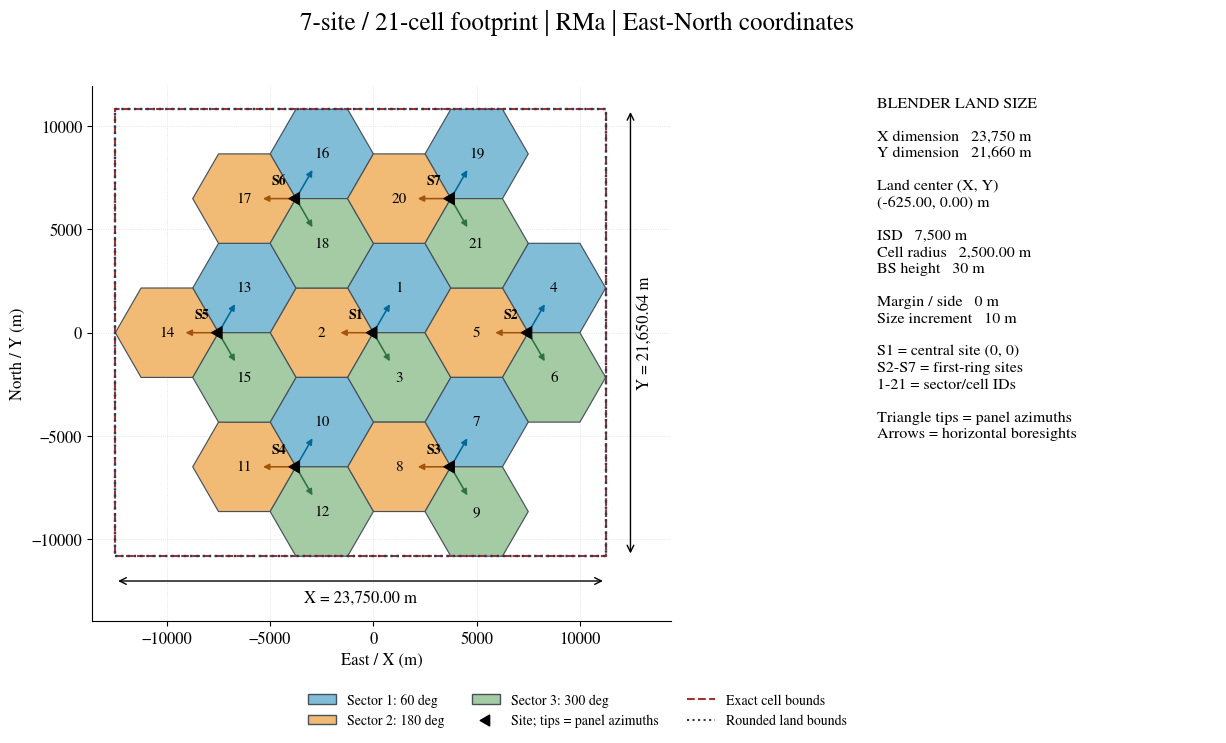

In [6]:
fig_layout = plt.figure(figsize=(13.6, 7.65))
grid = fig_layout.add_gridspec(1, 2, width_ratios=[3.2, 1.45],
                              left=0.08, right=0.97, bottom=0.16, top=0.86, wspace=0.22)
ax = fig_layout.add_subplot(grid[0])
info = fig_layout.add_subplot(grid[1])
info.axis('off')
draw_cells(ax, layout, label_cells=True, label_sites=True)
draw_rectangle(ax, tight)
draw_rectangle(ax, land, color='#293B59', linestyle=':', linewidth=1.7)

low, high = tight['min'], tight['max']
y_arrow = low[1] - 0.16 * ISD_M
x_arrow = high[0] + 0.16 * ISD_M
ax.annotate('', (low[0], y_arrow), (high[0], y_arrow),
            arrowprops={'arrowstyle': '<->', 'color': 'black'})
ax.text(tight['center'][0], y_arrow - 0.06 * ISD_M,
        f"X = {tight['size'][0]:,.2f} m", ha='center', va='top')
ax.annotate('', (x_arrow, low[1]), (x_arrow, high[1]),
            arrowprops={'arrowstyle': '<->', 'color': 'black'})
ax.text(x_arrow + 0.04 * ISD_M, tight['center'][1],
        f"Y = {tight['size'][1]:,.2f} m", rotation=90, ha='left', va='center')
plot_low = np.minimum(tight['min'], land['min'])
plot_high = np.maximum(tight['max'], land['max'])
ax.set_xlim(plot_low[0] - 0.15 * ISD_M, plot_high[0] + 0.42 * ISD_M)
ax.set_ylim(plot_low[1] - 0.42 * ISD_M, plot_high[1] + 0.15 * ISD_M)

lines = [
    'BLENDER LAND SIZE', '',
    f"X dimension   {land['size'][0]:,.0f} m",
    f"Y dimension   {land['size'][1]:,.0f} m", '',
    'Land center (X, Y)',
    f"({land['center'][0]:,.2f}, {land['center'][1]:,.2f}) m", '',
    f"ISD   {ISD_M:,.0f} m",
    f"Cell radius   {layout['radius_m']:,.2f} m",
    f"BS height   {BS_HEIGHT_M:g} m", '',
    f"Margin / side   {MARGIN_M:g} m",
    f"Size increment   {ROUND_UP_M:g} m", '',
    'S1 = central site (0, 0)',
    'S2-S7 = first-ring sites',
    '1-21 = sector/cell IDs', '',
    'Triangle tips = panel azimuths',
    'Arrows = horizontal boresights',
]
info.text(0, 0.98, '\n'.join(lines), va='top', fontsize=11.5, linespacing=1.30)
legend = [Patch(facecolor=COLORS[i], edgecolor='#46515B',
                label=f'Sector {i + 1}: {AZIMUTH_DEG[i]:g} deg') for i in range(3)]
legend += [Line2D([], [], color='black', marker=SITE_MARKER, markersize=9, linestyle='none',
                     label='Site; tips = panel azimuths'),
           Line2D([], [], color='#A33030', linestyle='--', label='Exact cell bounds'),
           Line2D([], [], color='#293B59', linestyle=':', label='Rounded land bounds')]
fig_layout.legend(handles=legend, loc='lower center', ncol=3, fontsize=10,
                  frameon=False, bbox_to_anchor=(0.5, 0.005))
fig_layout.suptitle(f'7-site / 21-cell footprint | {SCENARIO} | East-North coordinates',
                    fontsize=18, y=0.96)
fig_layout.savefig(OUT_DIR / 'tn_7site_cells_and_rectangle.png', dpi=200)
fig_layout.savefig(OUT_DIR / 'tn_7site_cells_and_rectangle.svg')
plt.show()

## Blender Modeling and Subsequent Cropping

1. Create a rectangle using the X and Y dimensions of the **Blender modeling area** above, with metres as the physical unit.
   In `tight` mode, place the land center at the reported `Land center`; the central site remains at `(0, 0)`.
   In `site_centered` mode, the land center is `(0, 0)`.
2. To move the `tight` land rectangle to the Blender origin, apply the same translation to **terrain, buildings, sites, cell vertices, and all subsequent transmitters and receivers**:
   `xy_new = xy_original - land['center']`.
   The exported CSV files include both original and translated coordinates to keep the two coordinate systems distinct.
3. This layout uses local ENU coordinates and is not yet tied to geographic coordinates. Once a real location is selected,
   use the same local origin and orientation for the map, terrain, and buildings.
   `BS_HEIGHT_M` is the antenna height above the reference ground; with real terrain, set the antenna Z coordinate using the ground elevation at each site.
4. The 21 hexagons define the simulation area and UE placement region. Their vertices in the JSON file can be used for subsequent cropping.
   The function below can also filter UE positions or radio-map grid points. Areas in the rectangle's corners that lie outside the cells are excluded from cell coverage.

The minimum rectangle guarantees geometric containment of all cells; it **does not guarantee preservation of all reflection and diffraction contributions from outside the region**.
Use `MARGIN_M` to add an environmental margin on each side; the appropriate margin depends on the real scene.
This notebook does not generate buildings, run ray tracing, or create the original model's periodic wrap-around replicas.


In [8]:
def inside_selected_cells(xy_m, tolerance_m=1e-8):
    """Return a mask for points in the union of the 21 original-coordinate cells."""
    points = np.asarray(xy_m, dtype=float)
    if points.shape[-1:] != (2,):
        raise ValueError('Expected an array with final dimension 2 (X, Y).')
    mask = np.zeros(points.shape[:-1], dtype=bool)
    radius = layout['radius_m']
    # Loop over cells to keep memory proportional to the input point count.
    for center in layout['centers']:
        local = points - center
        x, y = local[..., 0], local[..., 1]
        mask |= ((np.abs(y) <= np.sqrt(3) * radius / 2 + tolerance_m)
                 & (np.abs(np.sqrt(3) * x + y) <= np.sqrt(3) * radius + tolerance_m)
                 & (np.abs(np.sqrt(3) * x - y) <= np.sqrt(3) * radius + tolerance_m))
    return mask

# Example: convert a Blender-centered point back before applying the mask.
blender_centered_xy = layout['centers'] - land['center']
assert inside_selected_cells(blender_centered_xy + land['center']).all()
print('Crop helper ready: inside_selected_cells(points_in_original_xy_m)')

Crop helper ready: inside_selected_cells(points_in_original_xy_m)


In [9]:
# Validate geometry against the analytic bounds and the retained source sites.
assert layout['vertices'].shape == (21, 6, 2)
assert np.allclose(layout['sites'], layout19['sites'][:7])
assert np.allclose(np.linalg.norm(layout['sites'][1:], axis=1), ISD_M)
assert np.allclose(tight['size'], [19 * ISD_M / 6, 5 * np.sqrt(3) * ISD_M / 3])
assert np.allclose(tight['center'], [-ISD_M / 12, 0])
assert np.allclose(centered['size'], [10 * ISD_M / 3, 5 * np.sqrt(3) * ISD_M / 3])
assert np.all(layout['vertices'] >= land['min'] - 1e-8)
assert np.all(layout['vertices'] <= land['max'] + 1e-8)
assert inside_selected_cells(layout['centers']).all()
assert inside_selected_cells(layout['vertices'].reshape(-1, 2)).all()
assert not inside_selected_cells([[10 * ISD_M, 10 * ISD_M]])[0]


# Check every site-symbol tip and arrow against its sector direction.
for site_id in range(1, 8):
    site, rows, directions, tips, arrow_ends = site_symbol_geometry(layout, site_id)
    center_directions = layout['centers'][rows] - site
    center_directions /= np.linalg.norm(center_directions, axis=1, keepdims=True)
    for endpoints in (tips, arrow_ends):
        vectors = endpoints - site
        vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
        assert np.allclose(vectors, center_directions)

def export_csv(path, rows):
    with path.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

site_rows = []
for site_id, (x, y) in enumerate(layout['sites'], start=1):
    site_rows.append({'site_id': site_id, 'east_m': x, 'north_m': y,
                      'bs_height_above_ground_m': BS_HEIGHT_M,
                      'land_centered_x_m': x - land['center'][0],
                      'land_centered_y_m': y - land['center'][1]})
sector_rows = []
for i, site_id in enumerate(layout['site_ids']):
    x, y = layout['sites'][site_id - 1]
    cx, cy = layout['centers'][i]
    sector_rows.append({'sector_id': int(layout['sector_ids'][i]),
                       'site_id': int(site_id),
                       'sector_at_site': int(layout['sector_at_site'][i]),
                       'azimuth_from_east_ccw_deg': layout['azimuth_deg'][i],
                       'bearing_from_north_cw_deg': (90 - layout['azimuth_deg'][i]) % 360,
                       'horizontal_boresight_east_unit': unit_xy(layout['azimuth_deg'][i])[0],
                       'horizontal_boresight_north_unit': unit_xy(layout['azimuth_deg'][i])[1],
                       'bs_east_m': x, 'bs_north_m': y,
                       'bs_height_above_ground_m': BS_HEIGHT_M,
                       'cell_center_east_m': cx, 'cell_center_north_m': cy,
                       'bs_land_centered_x_m': x - land['center'][0],
                       'bs_land_centered_y_m': y - land['center'][1]})
export_csv(OUT_DIR / 'tn_sites.csv', site_rows)
export_csv(OUT_DIR / 'tn_sectors.csv', sector_rows)

def rectangle_json(rect):
    return {key + '_xy_m': value.tolist() for key, value in rect.items()}

payload = {
    'description': 'Center site plus six first-ring sites, three hexagonal cells per site',
    'scenario': SCENARIO, 'isd_m': ISD_M, 'cell_radius_m': layout['radius_m'],
    'coordinate_system': 'Local ENU; X east, Y north, Z up; coordinates in metres',
    'azimuth_convention': 'Counterclockwise from +X (east), in degrees',
    'site_symbol': 'Triangle vertices point along sector panel azimuths; symbol size is illustrative',
    'orientation_scope': 'Horizontal boresight projection only; downtilt and electrical steering are separate',
    'reference_documents': ['38863-j40.docx', '38901-j30.docx'],
    'georeferenced': False, 'number_of_sites': 7, 'number_of_cells': 21,
    'margin_each_side_m': MARGIN_M, 'dimension_rounding_m': ROUND_UP_M,
    'rectangle_mode': RECTANGLE_MODE,
    'tight_rectangle': rectangle_json(tight),
    'site_centered_rectangle': rectangle_json(centered),
    'blender_land': rectangle_json(land),
    'translation_original_to_land_centered_xy_m': (-land['center']).tolist(),
    'sites': site_rows,
    'cells': [dict(row, vertices_enu_xy_m=layout['vertices'][i].tolist())
              for i, row in enumerate(sector_rows)],
}
(OUT_DIR / 'tn_layout.json').write_text(json.dumps(payload, indent=2), encoding='utf-8')
print('Geometry and site-direction checks passed. Saved files:')
for filename in ['tn_19_to_7_sites.png', 'tn_7site_cells_and_rectangle.png',
                 'tn_7site_cells_and_rectangle.svg', 'tn_sites.csv',
                 'tn_sectors.csv', 'tn_layout.json']:
    print('  ' + str(OUT_DIR / filename))

Geometry and site-direction checks passed. Saved files:
  /home/shizhen/my_project/CL_Project/CL_Project/For NTN Nulling Simu/tn_7site_layout/tn_19_to_7_sites.png
  /home/shizhen/my_project/CL_Project/CL_Project/For NTN Nulling Simu/tn_7site_layout/tn_7site_cells_and_rectangle.png
  /home/shizhen/my_project/CL_Project/CL_Project/For NTN Nulling Simu/tn_7site_layout/tn_7site_cells_and_rectangle.svg
  /home/shizhen/my_project/CL_Project/CL_Project/For NTN Nulling Simu/tn_7site_layout/tn_sites.csv
  /home/shizhen/my_project/CL_Project/CL_Project/For NTN Nulling Simu/tn_7site_layout/tn_sectors.csv
  /home/shizhen/my_project/CL_Project/CL_Project/For NTN Nulling Simu/tn_7site_layout/tn_layout.json
